# ECE 9611 Project - Phase 1
## Brain tumour classification from MRI images

**Group:** 3  
**Members:** Tianqi Ni, Yuchen Zhao  
**Dataset:** #9 Brain Tumor MRI ([Kaggle](https://www.kaggle.com/datasets/deeppythonist/brain-tumor-mri-dataset))

**Problem:** given one MRI image, predict which of four classes it belongs to: glioma, meningioma, pituitary tumour or no tumour.

**Target:** the class, taken from the folder name.
**Unit:** one 2D image, not one patient. The dataset has no patient IDs.
**Main metric:** macro-F1, so each class counts equally. The test set is not evaluated in this phase.

## 1. Setup

In [1]:
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [3]:
SEED = 42
SIZE = (64, 64)
CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]
DATA = Path("data")
SPLIT_FILE = DATA / "splits.csv"

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
BAR_COLOR = "#2a78b5"

## 2. Load and audit the data

Every image in `train/` and `test/` is opened once. Test images are only used here for the quality and duplicate checks.

In [4]:
rows = []
for path in sorted(DATA.glob("*/*/*.jpg")):
    img = Image.open(path)
    small = img.convert("L").resize(SIZE)  # fails here if a file is corrupt
    rows.append({"path": path.as_posix(), "source": path.parts[1], "label": path.parts[2],
                 "width": img.width, "height": img.height, "mode": img.mode,
                 "bytes": path.stat().st_size,
                 "hash": hashlib.md5(small.tobytes()).hexdigest()})
df = pd.DataFrame(rows)

print("Table 1. Images per class in the supplied folders")
counts = pd.crosstab(df["label"], df["source"])
counts["total"] = counts.sum(axis=1)
display(counts)

Table 1. Images per class in the supplied folders


source,test,train,total
label,,,
glioma,324,1297,1621
meningioma,355,1420,1775
notumor,400,1600,2000
pituitary,351,1406,1757


In [5]:
# missingness and basic quality
print("Table 2. Quality checks")
display(pd.Series({
    "Images": len(df),
    "Empty files": int((df["bytes"] == 0).sum()),
    "Missing labels": int(df["label"].isna().sum()),
    "Labels outside the 4 classes": int((~df["label"].isin(CLASSES)).sum()),
    "Distinct image sizes": len(df[["width", "height"]].drop_duplicates()),
    "Colour modes": ", ".join(sorted(df["mode"].unique())),
}).to_frame("Value"))
print("Every file opened without error, or the loop above would have stopped.")
print("No tabular fields means no missing values to fill. Patient ID, scanner and age are not supplied.")

Table 2. Quality checks


,Value
Images,7153
Empty files,0
Missing labels,0
Labels outside the 4 classes,0
Distinct image sizes,387
Colour modes,"L, P, RGB, RGBA"


Every file opened without error, or the loop above would have stopped.
No tabular fields means no missing values to fill. Patient ID, scanner and age are not supplied.


In [6]:
# gaps: do the numbers in the filenames skip anything?
df["file_id"] = df["path"].str.extract(r"-(\d+)\.jpg$")[0].astype(int)
gaps = df.groupby("label")["file_id"].agg(images="count", highest_id="max")
gaps["missing_ids"] = gaps["highest_id"] - gaps["images"]
print("Table 3. Filename numbering, train and test combined")
display(gaps)

Table 3. Filename numbering, train and test combined


,images,highest_id,missing_ids
label,,,
glioma,1621,1621,0
meningioma,1775,1775,0
notumor,2000,2000,0
pituitary,1757,1757,0


### Duplicates

Two files count as duplicates if they give the same 64x64 grayscale image, since that is what the models see. A copy in both train and test would be leakage, so the test copy is kept and the others are dropped. Files on disk are not changed.

In [7]:
by_hash = df.groupby("hash")
print("Redundant copies:", len(df) - df["hash"].nunique())
print("Duplicate groups:", int((by_hash.size() > 1).sum()))
print("Groups crossing train and test:", int((by_hash["source"].nunique() > 1).sum()))
print("Groups with conflicting labels:", int((by_hash["label"].nunique() > 1).sum()))

# "test" sorts before "train", so the test copy is the one kept
clean = df.sort_values(["source", "path"]).drop_duplicates("hash")
print("Images left:", len(clean))

Redundant copies: 556
Duplicate groups: 409
Groups crossing train and test: 140
Groups with conflicting labels: 0
Images left: 6597


## 3. Train / validation / test split

The cleaned `test/` folder stays as the test set. The rest is split 75/25 with stratification, which gives roughly 60/20/20 overall. The split is saved the first time and reloaded after that, so it stays frozen.

In [8]:
if SPLIT_FILE.exists():
    splits = pd.read_csv(SPLIT_FILE)
else:
    dev = clean[clean["source"] == "train"]
    tr, val = train_test_split(dev["path"], test_size=0.25, stratify=dev["label"], random_state=SEED)
    splits = clean[["path", "label"]].assign(split="test")
    splits.loc[splits["path"].isin(tr), "split"] = "train"
    splits.loc[splits["path"].isin(val), "split"] = "validation"
    splits.to_csv(SPLIT_FILE, index=False)

assert set(splits["path"]) == set(clean["path"])
clean = clean.merge(splits[["path", "split"]], on="path")

In [9]:
print("Table 4. Frozen split")
table = pd.crosstab(clean["label"], clean["split"])[["train", "validation", "test"]]
table.loc["total"] = table.sum()
display(table)
print("Percent of images:", (table.loc["total"] / len(clean) * 100).round(1).to_dict())

train = clean[clean["split"] == "train"]
val = clean[clean["split"] == "validation"]

Table 4. Frozen split


split,train,validation,test
label,,,
glioma,973,324,323
meningioma,889,296,346
notumor,999,333,374
pituitary,1042,348,350
total,3903,1301,1393


Percent of images: {'train': 59.2, 'validation': 19.7, 'test': 21.1}


## 4. Exploring the training images

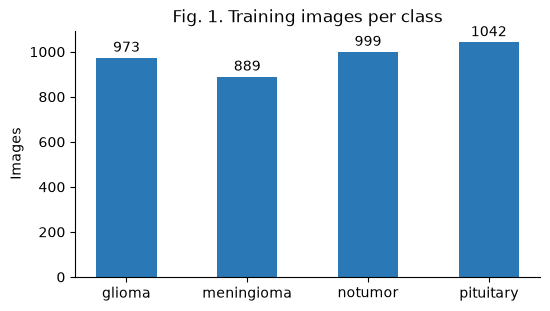

In [10]:
# Fig. 1
fig, ax = plt.subplots(figsize=(6, 3.2))
class_counts = train["label"].value_counts().reindex(CLASSES)
bars = ax.bar(CLASSES, class_counts, width=0.5, color=BAR_COLOR)
ax.bar_label(bars, padding=2)
ax.set(title="Fig. 1. Training images per class", ylabel="Images")
plt.show()

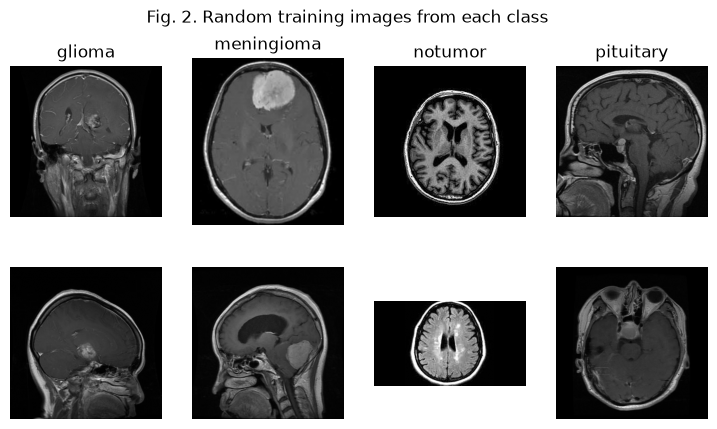

In [11]:
# Fig. 2
fig, axes = plt.subplots(2, 4, figsize=(9, 4.8))
for col, label in enumerate(CLASSES):
    samples = train[train["label"] == label].sample(2, random_state=SEED)
    for row, path in enumerate(samples["path"]):
        axes[row, col].imshow(Image.open(path).convert("L"), cmap="gray")
        axes[row, col].axis("off")
    axes[0, col].set_title(label)
fig.suptitle("Fig. 2. Random training images from each class")
plt.show()

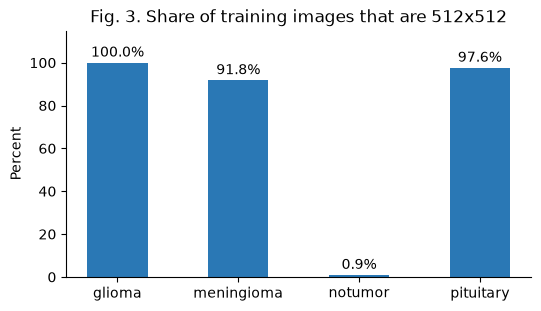

In [12]:
# Fig. 3
is_512 = (train["width"] == 512) & (train["height"] == 512)
share = is_512.groupby(train["label"]).mean().reindex(CLASSES) * 100

fig, ax = plt.subplots(figsize=(6, 3.2))
bars = ax.bar(CLASSES, share, width=0.5, color=BAR_COLOR)
ax.bar_label(bars, fmt="%.1f%%", padding=2)
ax.set(title="Fig. 3. Share of training images that are 512x512", ylabel="Percent", ylim=(0, 115))
plt.show()

**What the figures show**

- Fig. 1: the classes are fairly balanced (889 to 1042 images), so accuracy is not badly misleading. Macro-F1 is still the main metric.
- Fig. 2: the images mix axial, coronal and sagittal views, and some are not square. A pixel-based model has to cope with all of that.
- Fig. 3: almost all tumour images are 512x512, but only 0.9% of `notumor` images are. This suggests the no-tumour images came from a different source, so a model could partly learn the source and not the anatomy. Resizing hides the size itself, but differences in image quality or framing may remain.

## 5. Preprocessing

Each image becomes 64x64 grayscale, flattened to 4096 values between 0 and 1. A plain resize is used because padding would add black bars that give away the original shape. Test features are not built in this phase.

In [13]:
def load_features(frame):
    images = [np.asarray(Image.open(p).convert("L").resize(SIZE), dtype=np.float32) for p in frame["path"]]
    return np.stack(images).reshape(len(images), -1) / 255

X_train, y_train = load_features(train), train["label"].to_numpy()
X_val, y_val = load_features(val), val["label"].to_numpy()
print("Train:", X_train.shape, "| Validation:", X_val.shape)
print("Missing pixels:", int(np.isnan(X_train).sum()))

Train: (3903, 4096) | Validation: (1301, 4096)
Missing pixels: 0


The imputer and scaler are fit on the training data only and then applied to validation. No pixels are missing, so the imputer has nothing to do here. It stays in so every model gets the same steps.

`make_model` puts the same two steps in front of any classifier. Inside cross-validation, they are then refit on each training fold.

In [14]:
def make_model(clf):
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), clf)

prep = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(X_train)
print(f"Mean pixel after scaling - train: {prep.transform(X_train).mean():.4f}, validation: {prep.transform(X_val).mean():.4f}")

Mean pixel after scaling - train: 0.0000, validation: -0.0108


## 6. Smoke test

Quick checks on the split and preprocessing. They run in under a second once the cells above have run.

In [15]:
test = clean[clean["split"] == "test"]
assert (len(train), len(val), len(test)) == (3903, 1301, 1393)
assert not set(train["hash"]) & set(val["hash"])
assert not set(train["hash"]) & set(test["hash"])
assert not set(val["hash"]) & set(test["hash"])

# scaler was fit on training data only
assert np.allclose(prep[-1].mean_, X_train.mean(axis=0, dtype=np.float64))
assert np.isfinite(prep.transform(X_val)).all()
assert "X_test" not in globals()
print("All checks passed. Test features were never built.")

All checks passed. Test features were never built.


## Next

Cross-validation and regularization, the baseline models, the comparison table, error analysis, and the conclusion and risk come next. They all use `X_train`, `X_val` and `make_model` from above.

## Contributions and references

- **Tianqi Ni:** data audit, duplicates, split, exploratory figures, preprocessing
- **Yuchen Zhao:** baselines and model comparison

Used Claude Code for help with the code and write-up.